In [91]:
import os
import glob
import random
import shutil
from pathlib import Path
import cv2
import numpy as np

# ==== CONFIGURE PATHS ===============================
IMG_DIR = "C:/data/data_set/train/images"
LBL_DIR = "C:/data/data_set/train/labels"
NUM_SAMPLES = 5
ALPHA = 0.5
MASK_COLOR = (0, 0, 255)   # Red

# ==== OUTPUT DIRS ===================================
OUT_IMG_DIR  = Path("samples/images")
OUT_LBL_DIR  = Path("samples/labels")
OUT_VIZ_DIR  = Path("samples/visualizations")
OUT_MASK_DIR = Path("samples/masks")
OUT_IMG_DIR.mkdir(parents=True, exist_ok=True)
OUT_LBL_DIR.mkdir(parents=True, exist_ok=True)
OUT_VIZ_DIR.mkdir(parents=True, exist_ok=True)
OUT_MASK_DIR.mkdir(parents=True, exist_ok=True)

# ==== IMAGE-LABEL PAIRS =============================
img_files = sorted(glob.glob(os.path.join(IMG_DIR, "*.*")))
samples = []

for img_path in img_files:
    img_stem = Path(img_path).stem
    lbl_path = os.path.join(LBL_DIR, img_stem + ".txt")
    if os.path.isfile(lbl_path):
        samples.append((img_path, lbl_path))

if len(samples) == 0:
    raise RuntimeError("No valid image/label pairs found. Check your paths!")

# ==== PARSE POLYGON ANNOTATIONS =====================
def load_polygons(label_path, img_shape):
    H, W = img_shape[:2]
    polys = []
    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            coords = list(map(float, parts[1:]))
            if len(coords) < 6:
                continue  # Need at least 3 points for a polygon
            pts = np.array([[coords[i] * W, coords[i+1] * H] for i in range(0, len(coords), 2)], dtype=np.int32)
            polys.append(pts)
    return polys

# ==== VISUALIZE, SAVE IMAGES, LABELS, MASKS =========
for idx, (img_path, lbl_path) in enumerate(random.sample(samples, min(NUM_SAMPLES, len(samples)))):
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    mask_overlay = np.zeros_like(img_rgb)
    mask_bin = np.zeros(img.shape[:2], dtype=np.uint8)   # single channel for mask

    gt_polys = load_polygons(lbl_path, img.shape)
    if len(gt_polys) == 0:
        print(f"⚠️  No polygon mask in {os.path.basename(lbl_path)}. Skipping.")
        continue

    for pts in gt_polys:
        cv2.fillPoly(mask_overlay, [pts], color=MASK_COLOR)
        cv2.fillPoly(mask_bin, [pts], color=1)   # Binary mask: 1 for mask, 0 for background

    # File base name
    out_base = Path(img_path).stem

    # Save the overlay visualization as .png (with mask on the image)
    vis = cv2.addWeighted(mask_overlay, ALPHA, img_rgb, 1-ALPHA, 0)
    out_viz_path = OUT_VIZ_DIR / f"{out_base}_overlay.png"
    cv2.imwrite(str(out_viz_path), cv2.cvtColor(vis, cv2.COLOR_RGB2BGR))

    # Save the binary mask as .png
    out_mask_path = OUT_MASK_DIR / f"{out_base}_mask.png"
    cv2.imwrite(str(out_mask_path), mask_bin * 255)  # save as 0/255 uint8 mask

    # Save the GT RGB image (as PNG)
    out_img_path = OUT_IMG_DIR / f"{out_base}.png"
    cv2.imwrite(str(out_img_path), cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR))

    # Save/copy the label .txt file
    out_lbl_path = OUT_LBL_DIR / f"{out_base}.txt"
    shutil.copy(lbl_path, out_lbl_path)

    print(f"Saved: {out_img_path}, {out_lbl_path}, {out_viz_path}, {out_mask_path}")

print("\nAll images, masks, visualizations, and label files saved.")


Saved: samples\images\tile_5_3_jpg.rf.af825492563115c61d4a5c065f9ee432.png, samples\labels\tile_5_3_jpg.rf.af825492563115c61d4a5c065f9ee432.txt, samples\visualizations\tile_5_3_jpg.rf.af825492563115c61d4a5c065f9ee432_overlay.png, samples\masks\tile_5_3_jpg.rf.af825492563115c61d4a5c065f9ee432_mask.png
Saved: samples\images\tile_1_3_jpg.rf.87154f6cd79f3a85ca79b8d933d6311c.png, samples\labels\tile_1_3_jpg.rf.87154f6cd79f3a85ca79b8d933d6311c.txt, samples\visualizations\tile_1_3_jpg.rf.87154f6cd79f3a85ca79b8d933d6311c_overlay.png, samples\masks\tile_1_3_jpg.rf.87154f6cd79f3a85ca79b8d933d6311c_mask.png
Saved: samples\images\tile_2_5_jpg.rf.a9eacbee5e0800e47402174e0e37b00b.png, samples\labels\tile_2_5_jpg.rf.a9eacbee5e0800e47402174e0e37b00b.txt, samples\visualizations\tile_2_5_jpg.rf.a9eacbee5e0800e47402174e0e37b00b_overlay.png, samples\masks\tile_2_5_jpg.rf.a9eacbee5e0800e47402174e0e37b00b_mask.png
Saved: samples\images\tile_5_3_jpg.rf.e3425f90ce7a9445356c0ea608d89f5d.png, samples\labels\til

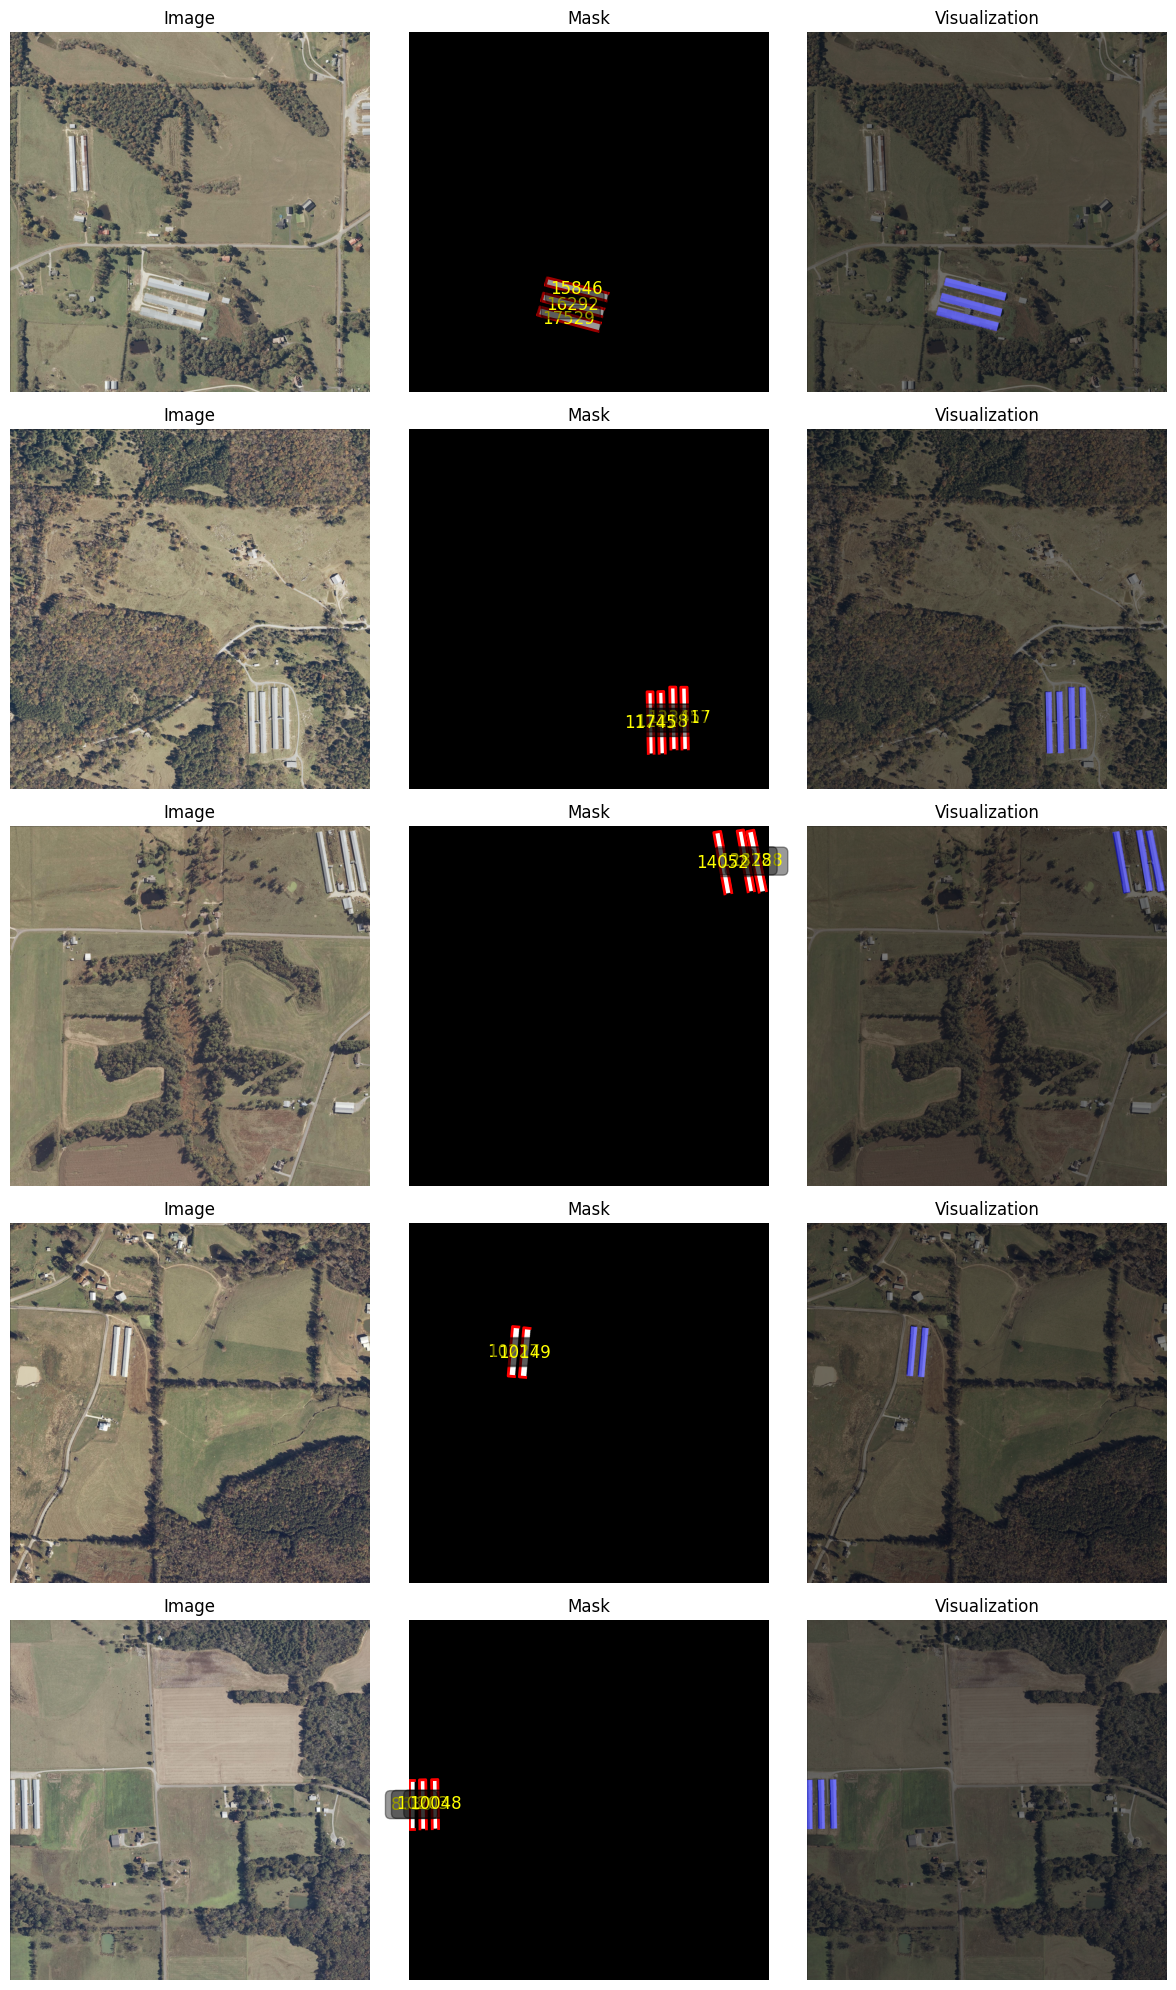

In [95]:
import matplotlib.pyplot as plt

viz_files = sorted(list(OUT_VIZ_DIR.glob("*_overlay.png")))
mask_files = sorted(list(OUT_MASK_DIR.glob("*_mask.png")))
img_files  = sorted(list(OUT_IMG_DIR.glob("*.png")))
lbl_files  = sorted(list(OUT_LBL_DIR.glob("*.txt")))

num_samples = min(NUM_SAMPLES, len(img_files))

fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4 * num_samples))

for i in range(num_samples):
    # Read
    img  = cv2.cvtColor(cv2.imread(str(img_files[i])), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(str(mask_files[i]), cv2.IMREAD_GRAYSCALE)
    viz  = cv2.cvtColor(cv2.imread(str(viz_files[i])), cv2.COLOR_BGR2RGB)
    lbl_path = lbl_files[i]
    # To recalculate polygon areas, reload polygons:
    def load_polygons(label_path, img_shape):
        H, W = img_shape[:2]
        polys = []
        with open(label_path) as f:
            for line in f:
                parts = line.strip().split()
                coords = list(map(float, parts[1:]))
                if len(coords) < 6:
                    continue  # Need at least 3 points for a polygon
                pts = np.array([[coords[i] * W, coords[i+1] * H] for i in range(0, len(coords), 2)], dtype=np.int32)
                polys.append(pts)
        return polys
    polygons = load_polygons(lbl_path, img.shape)
    # Calculate area for each polygon (in pixels)
    areas = []
    for pts in polygons:
        area = cv2.contourArea(pts)
        areas.append(area)

    # Display in grid
    ax_img = axes[i, 0] if num_samples > 1 else axes[0]
    ax_mask = axes[i, 1] if num_samples > 1 else axes[1]
    ax_viz = axes[i, 2] if num_samples > 1 else axes[2]

    # GT Image
    ax_img.imshow(img)
    ax_img.axis('off')
    ax_img.set_title("Image")

    # GT Mask with area labels
    ax_mask.imshow(mask, cmap='gray')
    ax_mask.axis('off')
    ax_mask.set_title("Mask")
    # Draw polygons & annotate area
    for j, pts in enumerate(polygons):
        # Draw polygon outline
        ax_mask.plot(pts[:,0], pts[:,1], color='red', linewidth=2)
        # Get centroid for text
        cx, cy = np.mean(pts, axis=0)
        ax_mask.text(cx, cy, f"{int(areas[j])}", color="yellow", fontsize=12, ha='center', va='center',
                     bbox=dict(facecolor='black', alpha=0.4, boxstyle='round'))

    # Overlay Visualization
    ax_viz.imshow(viz)
    ax_viz.axis('off')
    ax_viz.set_title("Visualization")

plt.tight_layout()
plt.show()

import pandas as pd
from pathlib import Path
import cv2
import numpy as np

IMG_DIR  = Path("samples/images")
LBL_DIR  = Path("samples/labels")
OUT_CSV  = "samples/groundTruth.csv"

img_files = sorted(list(IMG_DIR.glob("*.*")))

gt_rows = []
for img_path in img_files:
    img = cv2.imread(str(img_path))
    img_h, img_w = img.shape[:2]
    base = img_path.stem
    lbl_path = LBL_DIR / (base + ".txt")
    if not lbl_path.exists():
        continue

    with open(lbl_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 7:
                continue
            cls_id = int(parts[0])
            coords = list(map(float, parts[1:]))
            pts = np.array([[coords[i] * img_w, coords[i+1] * img_h] for i in range(0, len(coords), 2)], dtype=np.float32)
            area = cv2.contourArea(pts)
            x1, y1 = np.min(pts, axis=0)
            x2, y2 = np.max(pts, axis=0)
            mask_pts = [tuple(map(float, xy)) for xy in pts]
            gt_rows.append({
                "image": img_path.name,
                "class": cls_id,
                "conf": 1.0,
                "x1": float(x1),
                "y1": float(y1),
                "x2": float(x2),
                "y2": float(y2),
                "area_px": int(area),
                "mask_pts": mask_pts
            })

df_gt = pd.DataFrame(gt_rows)
df_gt.to_csv(OUT_CSV, index=False)
# print(f"Ground truth CSV saved to {OUT_CSV}")


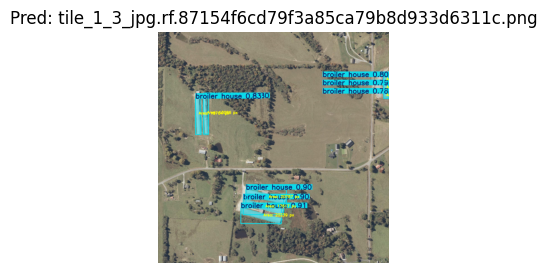

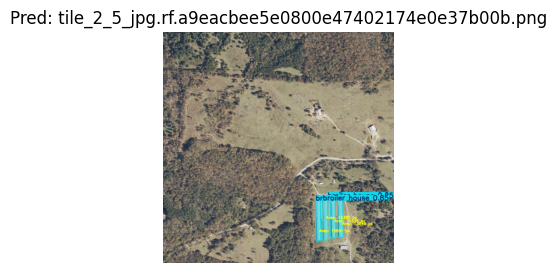

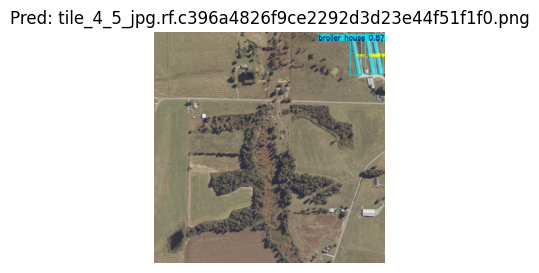

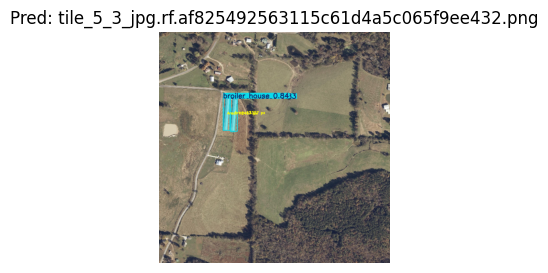

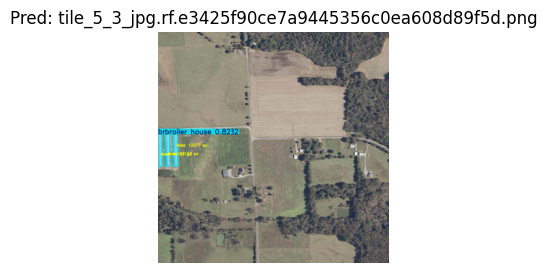

Saved predictions and visualization images in C:\Users\mza0288\Documents\Code\samples\predictions


In [93]:
from ultralytics import YOLO
import pandas as pd
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import os

# Path to your trained segmentation model
model = YOLO("C:/Users/mza0288/Documents/CODE/runs/segment/yolo11m-500-sgd-04092025/weights/best.pt")

# Get all images in samples/images directory
IMG_DIR = Path("samples/images")
PRED_DIR = Path("samples/predictions")
PRED_DIR.mkdir(parents=True, exist_ok=True)
img_paths = sorted(list(IMG_DIR.glob("*.*")))  # Supports .png, .jpg, etc.

# Run inference
results = model.predict(
    source=[str(img_path) for img_path in img_paths],
    imgsz=640, device="cuda", verbose=False
)

# Collect predictions and show/save visualizations
preds = []
for res in results:
    img_name = Path(res.path).name
    plotted = res.plot()  # This is **BGR** (YOLOv8 default)

    # ---- ALWAYS convert to RGB for matplotlib
    plotted_rgb = cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB)

    orig_img = cv2.imread(str(res.path))
    img_h, img_w = orig_img.shape[:2]

    boxes = res.boxes.xyxy.cpu().numpy()
    scores = res.boxes.conf.cpu().numpy()
    cls = res.boxes.cls.cpu().numpy().astype(int)
    polys = res.masks.xy  # List of (N,2) numpy arrays

    # --- Draw area annotations on plotted_rgb (which is now RGB)
    for i, (b, s, c) in enumerate(zip(boxes, scores, cls)):
        pts = np.array(polys[i], dtype=np.float32)
        area = cv2.contourArea(pts)
        preds.append({
            "image": img_name,
            "class":  c,
            "conf":   float(s),
            "x1":     float(b[0]),
            "y1":     float(b[1]),
            "x2":     float(b[2]),
            "y2":     float(b[3]),
            "area_px": int(area),
            "mask_pts": [tuple(map(float, xy)) for xy in pts]
        })
        cx, cy = np.mean(pts, axis=0)
        # Draw annotation ON RGB image, but OpenCV expects BGR color: (B, G, R)
        cv2.putText(plotted_rgb, f"Area: {int(area)} px", (int(cx), int(cy)),
                    fontFace=cv2.FONT_HERSHEY_SIMPLEX, fontScale=1.1, color=(255,255,0),  # Yellow in RGB
                    thickness=3, lineType=cv2.LINE_AA)

    # Save annotated image in predictions dir (convert back to BGR for cv2.imwrite)
    out_img_path = PRED_DIR / f"{Path(img_name).stem}_prediction.png"
    cv2.imwrite(str(out_img_path), cv2.cvtColor(plotted_rgb, cv2.COLOR_RGB2BGR))

    # Show image in Jupyter (matplotlib expects RGB)
    plt.figure(figsize=(3,3))
    plt.imshow(plotted_rgb)
    plt.axis("off")
    plt.title(f"Pred: {img_name}")
    plt.show()

# Save all predictions to CSV
df = pd.DataFrame(preds)
df.to_csv("samples/predictions.csv", index=False)
print(f"Saved predictions and visualization images in {PRED_DIR.resolve()}")


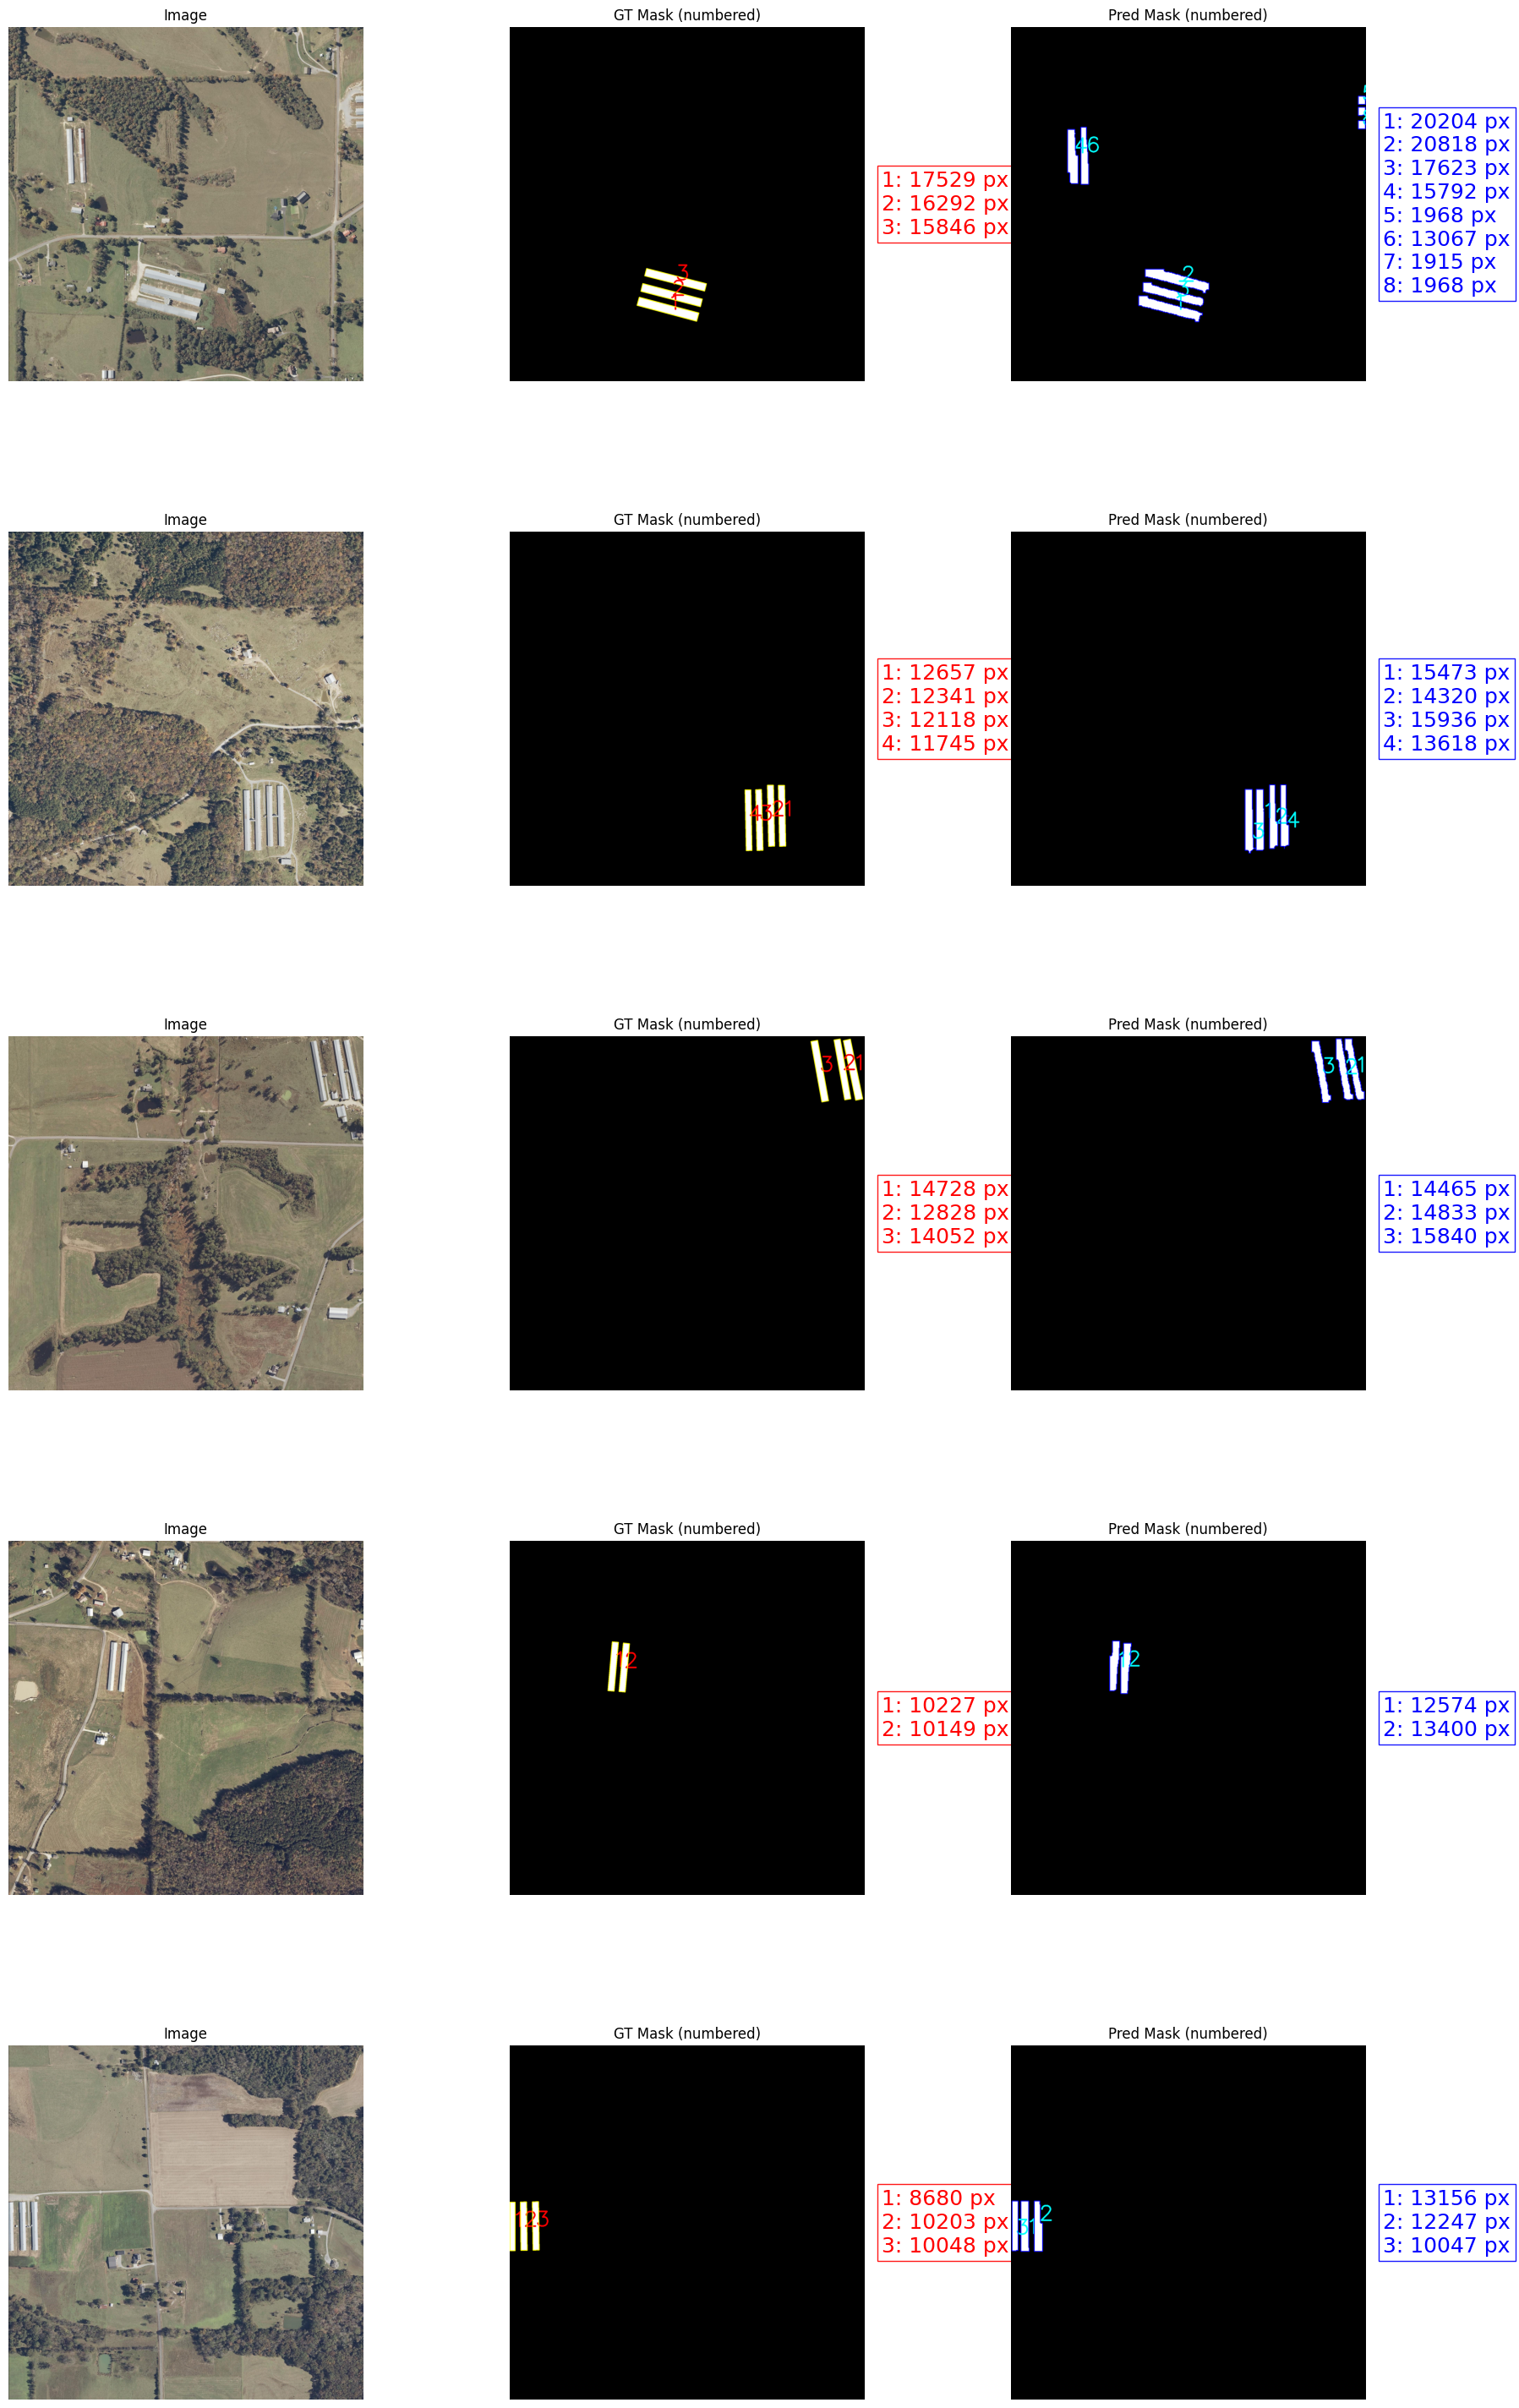

In [94]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
from pathlib import Path
from ultralytics import YOLO

# Paths
IMG_DIR  = Path("samples/images")
LBL_DIR  = Path("samples/labels")
MASK_COLOR = (0, 0, 255)
NUM_SAMPLES = 5

# --- Inference (comment out if already done) ---
model = YOLO("C:/Users/mza0288/Documents/CODE/runs/segment/yolo11m-500-sgd-04092025/weights/best.pt")
img_paths = sorted(list(IMG_DIR.glob("*.*")))
results = model.predict(source=[str(p) for p in img_paths], imgsz=640, device="cuda", verbose=False)

# --- Visualization Grid ---
def load_polygons(label_path, img_shape):
    H, W = img_shape[:2]
    polys = []
    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            coords = list(map(float, parts[1:]))
            if len(coords) < 6:
                continue
            pts = np.array([[coords[i] * W, coords[i+1] * H] for i in range(0, len(coords), 2)], dtype=np.int32)
            polys.append(pts)
    return polys

num_samples = min(NUM_SAMPLES, len(img_paths))
fig, axes = plt.subplots(num_samples, 3, figsize=(18, 6 * num_samples))

for idx in range(num_samples):
    img_path = img_paths[idx]
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    base = img_path.stem
    lbl_path = LBL_DIR / (base + ".txt")

    # --- Ground Truth Mask + Area ---
    mask_gt = np.zeros(img.shape[:2], dtype=np.uint8)
    gt_polys = load_polygons(lbl_path, img.shape)
    gt_areas = []
    gt_centroids = []
    for pts in gt_polys:
        cv2.fillPoly(mask_gt, [pts], color=255)
        gt_areas.append(int(cv2.contourArea(pts)))
        cx, cy = np.mean(pts, axis=0)
        gt_centroids.append((int(cx), int(cy)))
    # For annotation
    mask_gt_rgb = cv2.cvtColor(mask_gt, cv2.COLOR_GRAY2RGB)
    for j, pts in enumerate(gt_polys):
        cx, cy = gt_centroids[j]
        # Draw number (starting from 1)
        cv2.putText(mask_gt_rgb, f"{j+1}", (cx, cy),
                    fontFace=cv2.FONT_HERSHEY_SIMPLEX, fontScale=4, color=(255,0,0),
                    thickness=8, lineType=cv2.LINE_AA)
        cv2.polylines(mask_gt_rgb, [pts], isClosed=True, color=(255,255,0), thickness=3)

    # --- Prediction Mask + Area ---
    res = results[idx]
    mask_pred = np.zeros(img.shape[:2], dtype=np.uint8)
    pred_areas = []
    pred_centroids = []
    pred_polys = res.masks.xy if hasattr(res.masks, 'xy') else []
    for pts in pred_polys:
        pts_int = np.array(pts, dtype=np.int32)
        cv2.fillPoly(mask_pred, [pts_int], color=255)
        pred_areas.append(int(cv2.contourArea(pts_int)))
        cx, cy = np.mean(pts_int, axis=0)
        pred_centroids.append((int(cx), int(cy)))
    mask_pred_rgb = cv2.cvtColor(mask_pred, cv2.COLOR_GRAY2RGB)
    for j, pts in enumerate(pred_polys):
        pts_int = np.array(pts, dtype=np.int32)
        cx, cy = pred_centroids[j]
        cv2.putText(mask_pred_rgb, f"{j+1}", (cx, cy),
                    fontFace=cv2.FONT_HERSHEY_SIMPLEX, fontScale=4, color=(0,255,255),
                    thickness=8, lineType=cv2.LINE_AA)
        cv2.polylines(mask_pred_rgb, [pts_int], isClosed=True, color=(0,0,255), thickness=3)

    # --- Show in Grid ---
    ax_img = axes[idx, 0] if num_samples > 1 else axes[0]
    ax_mask = axes[idx, 1] if num_samples > 1 else axes[1]
    ax_pred = axes[idx, 2] if num_samples > 1 else axes[2]

    ax_img.imshow(img)
    ax_img.axis('off')
    ax_img.set_title("Image")

    # GT Mask with legend
    ax_mask.imshow(mask_gt_rgb)
    ax_mask.axis('off')
    ax_mask.set_title("GT Mask (numbered)")
    # Add legend
    legend_gt = "\n".join([f"{j+1}: {area} px" for j, area in enumerate(gt_areas)])
    ax_mask.text(1.05, 0.5, legend_gt, transform=ax_mask.transAxes,
                 fontsize=18, va='center', color='red',
                 bbox=dict(facecolor='white', alpha=0.9, edgecolor='red'))

    # Pred Mask with legend
    ax_pred.imshow(mask_pred_rgb)
    ax_pred.axis('off')
    ax_pred.set_title("Pred Mask (numbered)")
    # Add legend
    legend_pred = "\n".join([f"{j+1}: {area} px" for j, area in enumerate(pred_areas)])
    ax_pred.text(1.05, 0.5, legend_pred, transform=ax_pred.transAxes,
                 fontsize=18, va='center', color='blue',
                 bbox=dict(facecolor='white', alpha=0.9, edgecolor='blue'))

plt.tight_layout()
plt.show()
